Ejercicio conexión SQL - Python 2 (conexión con base existente)
EJERCICIOS TEMA 3 - CONEXIÓN A BASE DE DATOS SQL EXISTENTE DESDE JUPYTER NOTEBOOK
Conexión a base de datos relacional ya existente en Python
Para la realización de estos ejercicios, se requiere:

Instalar el paquete mysql.connector.
Tener instalado y configurado un servidor MySQL en localhost.
Tener presente que se supone que el usuario y la contraseña de autenticación en el servidor son root y root.
El objetivo de esta práctica es conectarse a una base de datos relacional ya existente en MySQL, realizar una consulta, e importar la información a un dataframe de pandas.

1. Importar las librerías

In [1]:
%pip install mysql.connector
%pip install numpy
%pip install pandas
%pip install matplotlib.pyplot
%pip install seaborn

import mysql.connector as connection
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement matplotlib.pyplot (from versions: none)
ERROR: No matching distribution found for matplotlib.pyplot


Note: you may need to restart the kernel to use updated packages.


2. Establecer la conexión con la base de datos

In [20]:
mydb = connection.connect(host='localhost', user='root', password="", db='spotify_final')

3.1 ¿Qué artistas tienen, en promedio, las canciones más populares dentro del dataset?

In [23]:

# 1. ¿Qué artistas tienen, en promedio, las canciones más populares?
query1 = """
SELECT Nombre_Art, AVG(popularidad) AS avg_popularidad
FROM cancion
GROUP BY Nombre_Art
ORDER BY avg_popularidad DESC
LIMIT 10;
"""
print("1. Artistas con canciones más populares en promedio:")
print(pd.read_sql_query(query1, mydb))


1. Artistas con canciones más populares en promedio:


C:\Users\clait\AppData\Local\Temp\ipykernel_6152\54447184.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql_query(query1, mydb))


DatabaseError: Execution failed on sql '
SELECT Nombre_Art, AVG(popularidad) AS avg_popularidad
FROM cancion
GROUP BY Nombre_Art
ORDER BY avg_popularidad DESC
LIMIT 10;
': 1054 (42S22): Unknown column 'Nombre_Art' in 'field list'

4. Curación y Limpieza de la base de datos

In [4]:
# Tipos de las variables
df_query.dtypes

ID_E                      int64
DIR                      object
TIPO                     object
Nivel_Calidad             int64
Categoria                 int64
ID_T                      int64
ID_E                      int64
Fecha_Inicio     datetime64[ns]
Num_Dias                  int64
dtype: object

In [5]:
# Conversión a tipos adecuados
str_= ['DIR']
cat_= ['TIPO', 'Nivel_Calidad', 'Categoria']

df_query[str_]= df_query[str_].astype('string')
df_query[cat_]= df_query[cat_].astype('category').fillna(np.nan)

df_query.dtypes

ID_E                      int64
DIR                      string
TIPO                   category
Nivel_Calidad          category
Categoria              category
ID_T                      int64
ID_E                      int64
Fecha_Inicio     datetime64[ns]
Num_Dias                  int64
dtype: object

In [6]:
# Valores perdidos
df_query.isnull().sum()

ID_E              0
DIR               0
TIPO              0
Nivel_Calidad     0
Categoria         0
ID_T              0
ID_E              0
Fecha_Inicio     10
Num_Dias          0
dtype: int64

5. Exploring Data Analysis (EDA)

In [7]:
# Estadísticos descriptivos del Número de Días
round(df_query['Num_Dias'].describe(),2)

count    19.00
mean     13.68
std       5.45
min       4.00
25%      10.00
50%      14.00
75%      17.50
max      24.00
Name: Num_Dias, dtype: float64

TIPO,count (n),percentage (%)
Almacen,3,15.79
Comercio,3,15.79
Oficina,10,52.63
Residencia,3,15.79
NA,0,0.00
TOTAL,19,100.00


Nivel_Calidad,count (n),percentage (%)
1,3,15.79
2,4,21.05
3,9,47.37
4,3,15.79
NA,0,0.00
TOTAL,19,100.00


Categoria,count (n),percentage (%)
1,9,47.37
2,7,36.84
3,3,15.79
NA,0,0.00
TOTAL,19,100.00


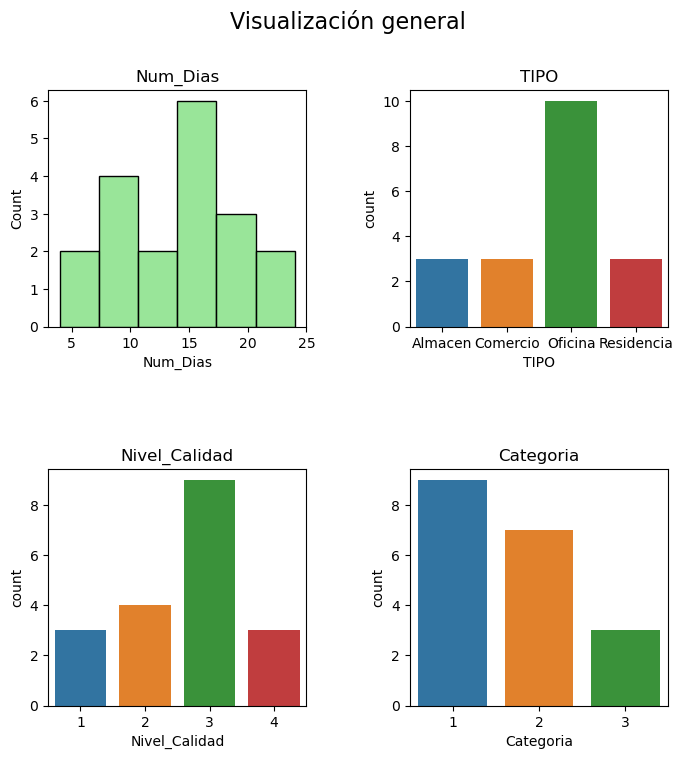

In [8]:
# Tablas de frecuencias de las variables categóricas
def freqtab (df, column, decimals):
    
    df2= df.copy()
    df2[column]= df2[column].cat.add_categories('NA')
    table= pd.crosstab(index=df2[column].fillna('NA'), columns='count', dropna=False)

    table.rename(columns={'count':'count (n)'}, inplace=True)
    table['percentage (%)']= [float(round((value/sum(table['count (n)'].values.tolist())*100),decimals)) for value in table['count (n)'].values.tolist()]
    total= pd.DataFrame(data=[[sum(table['count (n)'].values.tolist()), sum(table['percentage (%)'].values.tolist())]], columns=table.columns.to_list(), index=['TOTAL'])
    table= pd.concat([table,total], axis=0)
    table= table.rename_axis(column, axis=1)

    return table


display(freqtab (df=df_query, column='TIPO', decimals=2))
display(freqtab (df=df_query, column='Nivel_Calidad', decimals=2))
display(freqtab (df=df_query, column='Categoria', decimals=2))
vars_= ['Num_Dias', 'TIPO', 'Nivel_Calidad', 'Categoria']

fig,axs= plt.subplots(nrows=2,ncols=2,figsize=(8,8))
fig.suptitle('Visualización general', size=16)

counter=0
for i in range(2):
    for j in range(2):
        axs[i,j].set_title(vars_[counter])
        if counter == 0:
            sns.histplot(data=df_query, x=vars_[counter], color='#77DD77', ax=axs[i,j])
        elif counter > 0:
            sns.countplot(data=df_query, x=vars_[counter], ax=axs[i,j])
        counter+=1
        
plt.subplots_adjust(wspace=0.4, hspace=0.6)
plt.show()